# Universal Approximation Theorem

### How many neurons do you actually need?

The theorem establishes that a single hidden layer with a nonlinear activation can approximate any continuous function on a bounded domain, given sufficient width. However, the theorem is an existence result — it guarantees that suitable weights exist, not that gradient descent will find them, and not that the resulting model will generalize. 

To make this concrete, we fit a three-frequency target function with networks of width 2, 5, 20, and 100, observe MSE falling monotonically as width increases, and then systematically isolate the four failure modes: absent nonlinearity, excessive learning rate, insufficient learning rate, and inadequate width. Each failure mode is demonstrated with runnable code and its symptom documented.

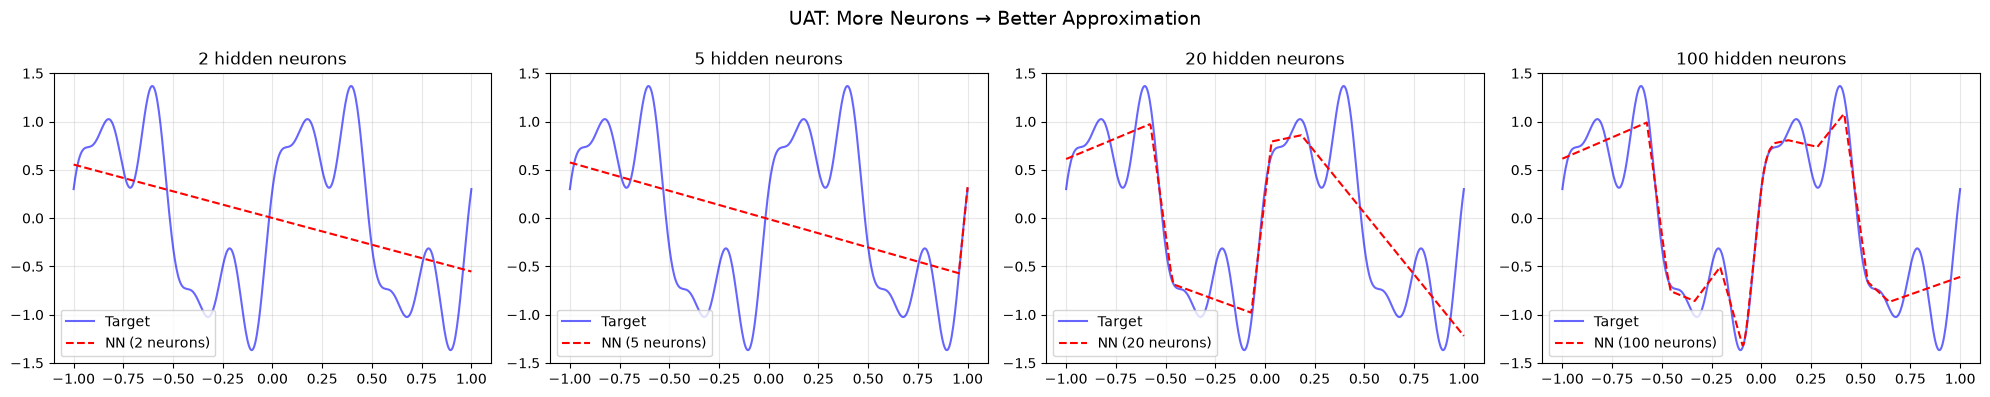

In [2]:
# Import libraries
import numpy as np                                        # numerical ops + target function
import matplotlib.pyplot as plt                           # 1x4 panel plot
import torch                                              # tensors + autograd
import torch.nn as nn                                     # layers

def target_function(x):                                   # the function we want to approximate
    """Sum of three sinusoids at different frequencies."""
    return (np.sin(2 * np.pi * x)                         # slow wave (period 1)
            + 0.5 * np.sin(6 * np.pi * x)                 # medium wave (period 1/3)
            + 0.3 * np.cos(10 * np.pi * x))               # fast wave (period 1/5)

np.random.seed(42)                                        # reproducibility
x_data = np.linspace(-1, 1, 500).reshape(-1, 1).astype(np.float32)   # 500 inputs in [-1,1]
y_data = target_function(x_data).astype(np.float32)       # targets for those inputs
X = torch.tensor(x_data)                                  # wrap for PyTorch
y = torch.tensor(y_data)

class UATNet(nn.Module):                                  # one hidden layer, variable width
    def __init__(self, n_hidden):                         # n_hidden = number of neurons
        super().__init__()                                # register nn.Module internals
        self.hidden = nn.Linear(1, n_hidden)              # input 1 → hidden n_hidden
        self.output = nn.Linear(n_hidden, 1)              # hidden → output (regression → 1)

    def forward(self, x):                                 # what flows through the net
        x = torch.relu(self.hidden(x))                    # NONLINEARITY — without this, linear
        return self.output(x)                             # no output activation (regression)

neuron_counts = [2, 5, 20, 100]                           # widths to test (capacity sweep)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))           # one panel per width

for ax, n in zip(axes, neuron_counts):                    # loop over widths
    model = UATNet(n)                                     # fresh net for each width
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  
    criterion = nn.MSELoss()                              # regression loss

    model.train()                                         # TRAIN MODE: enable dropout/bn training
    for epoch in range(3000):                             # 3000 weight updates
        optimizer.zero_grad()                             # clear old grads (accumulate otherwise)
        pred = model(X)                                   # forward pass
        loss = criterion(pred, y)                         # scalar MSE
        loss.backward()                                   # autograd — computes all ∂L/∂θ
        optimizer.step()                                  # W ← W − α·∂L/∂W, B ← B − α·∂L/∂B

    model.eval()                                          # INFERENCE MODE: dropout off, bn frozen
    with torch.no_grad():                                 # no graph needed for inference
        pred = model(X).numpy()                           # detach and convert to NumPy

    ax.plot(x_data, y_data, 'b-', label='Target', alpha=0.6)      # ground truth
    ax.plot(x_data, pred, 'r--', label=f'NN ({n} neurons)')       # approximation
    ax.set_title(f'{n} hidden neurons')                   # panel title
    ax.legend()                                           # show labels
    ax.grid(alpha=0.3)                                    # light grid

plt.suptitle('UAT: More Neurons → Better Approximation', fontsize=14)
plt.tight_layout()                                        # avoid overlapping subplots
plt.show()

### Alternatives

In [3]:
# ALTERNATIVE 1: Sigmoid hidden activation 
class UATNetSigmoid(nn.Module):
    def __init__(self, n_hidden):
        super().__init__()
        self.hidden = nn.Linear(1, n_hidden)              
        self.output = nn.Linear(n_hidden, 1)              
    def forward(self, x):
        x = torch.sigmoid(self.hidden(x))                 
        return self.output(x)

# ALTERNATIVE 2: Tanh hidden (zero-centered)
class UATNetTanh(nn.Module):
    def __init__(self, n_hidden):
        super().__init__()
        self.hidden = nn.Linear(1, n_hidden)
        self.output = nn.Linear(n_hidden, 1)
    def forward(self, x):
        x = torch.tanh(self.hidden(x))                    # zero-centered, still saturates
        return self.output(x)

# ALTERNATIVE 3: Deeper + thinner 
class UATDeep(nn.Module):
    def __init__(self, width=10, depth=3):                # small width × more layers
        super().__init__()
        layers = [nn.Linear(1, width), nn.ReLU()]         # stem
        for _ in range(depth - 1):                        # more hidden blocks
            layers += [nn.Linear(width, width), nn.ReLU()]
        layers.append(nn.Linear(width, 1))                # output
        self.net = nn.Sequential(*layers)                 # chain
    def forward(self, x):
        return self.net(x)                                # single call

# ALTERNATIVE 4: Leaky ReLU 
class UATNetLeaky(nn.Module):
    def __init__(self, n_hidden, slope=0.01):
        super().__init__()
        self.hidden = nn.Linear(1, n_hidden)
        self.output = nn.Linear(n_hidden, 1)
        self.slope = slope
    def forward(self, x):
        x = nn.functional.leaky_relu(self.hidden(x), self.slope)   # small slope for negatives
        return self.output(x)

# ALTERNATIVE 5: GELU
class UATNetGELU(nn.Module):
    def __init__(self, n_hidden):
        super().__init__()
        self.hidden = nn.Linear(1, n_hidden)
        self.output = nn.Linear(n_hidden, 1)
    def forward(self, x):
        x = nn.functional.gelu(self.hidden(x))            # smooth non-monotonic
        return self.output(x)

# SWEEP: quick comparison of all activations
torch.manual_seed(1234)                                      # reproducibility
results = {}
for name, NetClass in [("relu", UATNet), ("sigmoid", UATNetSigmoid),
                       ("tanh", UATNetTanh), ("leaky", UATNetLeaky),
                       ("gelu", UATNetGELU)]:
    m = NetClass(20)                                      # 20 neurons
    opt = torch.optim.Adam(m.parameters(), lr=0.01)       # same optimizer
    crit = nn.MSELoss()                                   # same loss
    m.train()                                             # TRAIN MODE
    for _ in range(1500):                                 # shorter to keep blog fast
        opt.zero_grad(); loss = crit(m(X), y); loss.backward(); opt.step()
    results[name] = loss.item()                           # record final MSE
print(results)                                            # compare

{'relu': 0.2240760326385498, 'sigmoid': 0.14740419387817383, 'tanh': 0.1220279335975647, 'leaky': 0.07887496799230576, 'gelu': 0.15582117438316345}


| Alternative | Use case | Why we might pick it |
| :--- | :--- | :--- |
| Sigmoid | Historic, smooth | Small nets, interpretable |
| Tanh | Zero-centered | RNN hidden states, older nets |
| ReLU (primary) | Modern default | Cheap, no positive saturation |
| Leaky ReLU | Dying ReLU fix | When many neurons stay at 0 |
| GELU | Transformers | Smooth, empirical wins |
| Deeper + thin | Model compression / compute-constrained deployment | Same capacity, fewer params |

### What could go wrong?

#### Failure 1: No nonlinearity -> whole deep net is one linear layer

In [ ]:
torch.manual_seed(0)                                      # reproduce

net = nn.Sequential(nn.Linear(1, 64),                     # linear
                    nn.Linear(64, 64),                    # linear — forgot ReLU!
                    nn.Linear(64, 1))                     # linear
opt = torch.optim.Adam(net.parameters(), lr=0.01)

net.train()                                               # TRAIN MODE
for _ in range(3000):
    opt.zero_grad(); loss = nn.MSELoss()(net(X), y); loss.backward(); opt.step()
print(f"No-activation MSE: {loss.item():.5f}")            # ~0.35 — can't fit wiggles
# Reason: composing linear maps gives a linear map 

No-activation MSE: 0.56626


- Stack of nn.Linear = one big nn.Linear (composition of linear maps is linear)
- Symptom: MSE plateaus ~0.55, fit looks like a straight line
- Deeper does not help — that's the giveaway
- Fix: add nn.ReLU() between every linear layer

No nonlinearity — Stacking nn.Linear layers without an activation collapses the whole net into a single linear map, so MSE plateaus at ~0.566 and the fit is a straight line.

In [9]:
# BROKEN
net = nn.Sequential(nn.Linear(1,64), nn.Linear(64,64), nn.Linear(64,1))

# FIXED
net = nn.Sequential(nn.Linear(1,64), nn.ReLU(),
                    nn.Linear(64,64), nn.ReLU(),
                    nn.Linear(64,1))

#### FAILURE 2: Learning rate too high → NaN within steps

In [ ]:
torch.manual_seed(0)

m = nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Linear(32, 1))
opt = torch.optim.SGD(m.parameters(), lr=10.0)            # absurd LR

m.train()                                                 # TRAIN MODE
for step in range(20):                                    # iterate
    opt.zero_grad(); loss = nn.MSELoss()(m(X), y); loss.backward(); opt.step()
    if torch.isnan(loss):                                 # check divergence
        print(f"NaN at step {step}"); break               # stops within a few steps

- Update θ ← θ − α∇L overshoots → loss grows → grads grow → ∞ → NaN
- Symptom: finite loss for a few steps, then NaN within ~10 steps
- Fix: sane LR (1e-2 Adam / 1e-1 SGD) + gradient clipping as safety net

LR too high — Overshooting the minimum with lr=10.0 makes loss grow each step until gradients explode to inf and the loss becomes NaN within ~10 steps.

In [10]:
# BROKEN
opt = torch.optim.SGD(m.parameters(), lr=10.0)

# FIXED
opt = torch.optim.SGD(m.parameters(), lr=0.01)
# ...inside loop after loss.backward():
torch.nn.utils.clip_grad_norm_(m.parameters(), max_norm=1.0)

tensor(9.8316e-06)

#### FAILURE 3: Learning rate too low → plateau

In [ ]:
torch.manual_seed(0)

m = nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Linear(32, 1))
opt = torch.optim.SGD(m.parameters(), lr=1e-8)            # tiny
m.train()                                                 # TRAIN MODE
for _ in range(3000):
    opt.zero_grad(); loss = nn.MSELoss()(m(X), y); loss.backward(); opt.step()
print(f"lr=1e-8 MSE: {loss.item():.5f}")                  # barely moves

lr=1e-8 MSE: 0.62243


- Update smaller than float32 resolution → weights round back to original
- Symptom: MSE frozen at init value (~0.62), never decreases
- Fix: raise LR, use Adam (adaptive), or warmup scheduler

LR too low — With lr=1e-8, updates are smaller than float32 resolution so weights round back to their initial values and MSE stays frozen at ~0.62.

In [11]:
# BROKEN
opt = torch.optim.SGD(m.parameters(), lr=1e-8)

# FIXED
opt = torch.optim.Adam(m.parameters(), lr=0.01)

#### FAILURE 4: Too few neurons → capacity insufficient 

In [ ]:
torch.manual_seed(0)

m = nn.Sequential(nn.Linear(1, 2), nn.ReLU(), nn.Linear(2, 1))   # only 2 neurons
opt = torch.optim.Adam(m.parameters(), lr=0.01)
m.train()                                                 # TRAIN MODE
for _ in range(3000):
    opt.zero_grad(); loss = nn.MSELoss()(m(X), y); loss.backward(); opt.step()
print(f"2-neuron MSE: {loss.item():.5f}")               

2-neuron MSE: 0.66884


- n ReLU units ⇒ ≤ n+1 linear regions; target has ~20+ bends
- Symptom: MSE ~0.66, coarse V-shaped fit
- Fix: increase width (≥20 works; 100 ≈ exact)


Too few neurons — An n-unit ReLU layer has at most n+1 linear regions, so 2 neurons give MSE ~0.669 (coarse V-shape) while 100 neurons fit the target almost exactly.

In [12]:
# BROKEN
m = nn.Sequential(nn.Linear(1,2), nn.ReLU(), nn.Linear(2,1))

# FIXED
m = nn.Sequential(nn.Linear(1,100), nn.ReLU(), nn.Linear(100,1))

- UAT = existence, not discoverability — weights exist, but optimizer must find them
- Nonlinearity is the load-bearing wall — remove it, depth buys nothing
- LR is diagnostic: NaN = too high · frozen = too low · plateau at high MSE = net too small

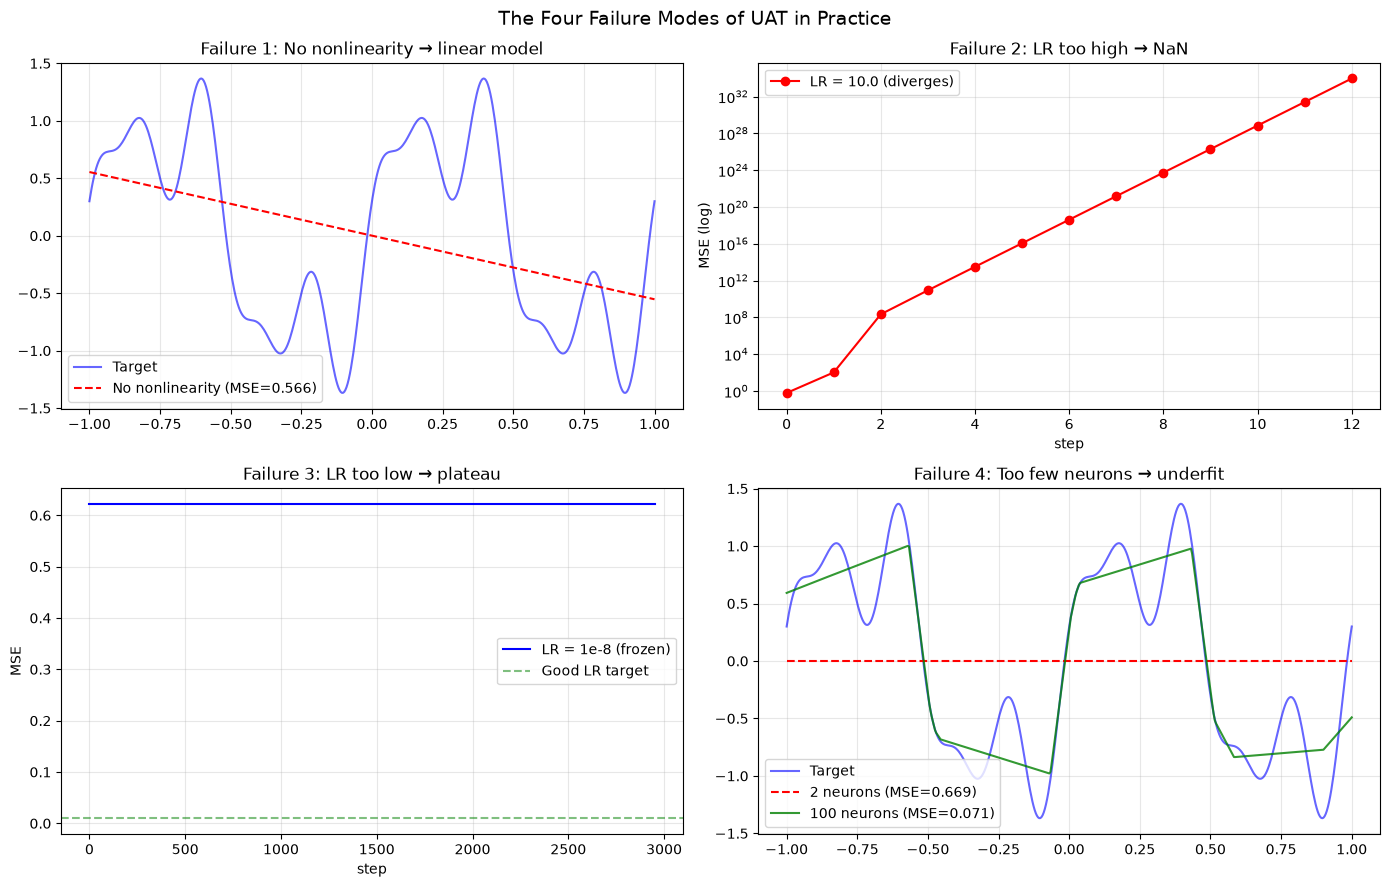

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ---- data (same as notebook) ----
def target_function(x):
    return np.sin(2*np.pi*x) + 0.5*np.sin(6*np.pi*x) + 0.3*np.cos(10*np.pi*x)

np.random.seed(1234)
x_data = np.linspace(-1, 1, 500).reshape(-1, 1).astype(np.float32)
y_data = target_function(x_data).astype(np.float32)
X = torch.tensor(x_data)
y = torch.tensor(y_data)

def train_and_pred(model, optimizer, steps=3000, clip=False):
    model.train()
    loss = None
    for _ in range(steps):
        optimizer.zero_grad()
        loss = nn.MSELoss()(model(X), y)
        loss.backward()
        if clip:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
    model.eval()
    with torch.no_grad():
        pred = model(X).numpy()
    return pred, (loss.item() if loss is not None else float('nan'))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# ---------- Failure 1: no nonlinearity ----------
torch.manual_seed(0)
m1 = nn.Sequential(nn.Linear(1,64), nn.Linear(64,64), nn.Linear(64,1))
p1, l1 = train_and_pred(m1, torch.optim.Adam(m1.parameters(), lr=0.01))
axes[0,0].plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
axes[0,0].plot(x_data, p1, 'r--', label=f'No nonlinearity (MSE={l1:.3f})')
axes[0,0].set_title('Failure 1: No nonlinearity → linear model')
axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

# ---------- Failure 2: LR too high ----------
torch.manual_seed(0)
m2 = nn.Sequential(nn.Linear(1,32), nn.ReLU(), nn.Linear(32,1))
opt2 = torch.optim.SGD(m2.parameters(), lr=10.0)
losses2 = []
m2.train()
for step in range(20):
    opt2.zero_grad()
    loss = nn.MSELoss()(m2(X), y)
    loss.backward(); opt2.step()
    losses2.append(loss.item())
    if torch.isnan(loss):
        break
axes[0,1].plot(losses2, 'r-o', label='LR = 10.0 (diverges)')
axes[0,1].set_yscale('log')
axes[0,1].set_title('Failure 2: LR too high → NaN')
axes[0,1].set_xlabel('step'); axes[0,1].set_ylabel('MSE (log)')
axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

# ---------- Failure 3: LR too low ----------
torch.manual_seed(0)
m3 = nn.Sequential(nn.Linear(1,32), nn.ReLU(), nn.Linear(32,1))
opt3 = torch.optim.SGD(m3.parameters(), lr=1e-8)
losses3 = []
m3.train()
for step in range(3000):
    opt3.zero_grad()
    loss = nn.MSELoss()(m3(X), y)
    loss.backward(); opt3.step()
    if step % 50 == 0:
        losses3.append(loss.item())
axes[1,0].plot(np.arange(len(losses3))*50, losses3, 'b-', label='LR = 1e-8 (frozen)')
axes[1,0].axhline(0.01, color='g', ls='--', alpha=0.5, label='Good LR target')
axes[1,0].set_title('Failure 3: LR too low → plateau')
axes[1,0].set_xlabel('step'); axes[1,0].set_ylabel('MSE')
axes[1,0].legend(); axes[1,0].grid(alpha=0.3)

# ---------- Failure 4: too few neurons ----------
torch.manual_seed(0)
m4 = nn.Sequential(nn.Linear(1,2), nn.ReLU(), nn.Linear(2,1))
p4, l4 = train_and_pred(m4, torch.optim.Adam(m4.parameters(), lr=0.01))
torch.manual_seed(0)
m4b = nn.Sequential(nn.Linear(1,100), nn.ReLU(), nn.Linear(100,1))
p4b, l4b = train_and_pred(m4b, torch.optim.Adam(m4b.parameters(), lr=0.01))
axes[1,1].plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
axes[1,1].plot(x_data, p4, 'r--', label=f'2 neurons (MSE={l4:.3f})')
axes[1,1].plot(x_data, p4b, 'g-', alpha=0.8, label=f'100 neurons (MSE={l4b:.3f})')
axes[1,1].set_title('Failure 4: Too few neurons → underfit')
axes[1,1].legend(); axes[1,1].grid(alpha=0.3)

plt.suptitle('The Four Failure Modes of UAT in Practice', fontsize=14)
plt.tight_layout()
plt.show()

=== 1. Capacity sweep ===


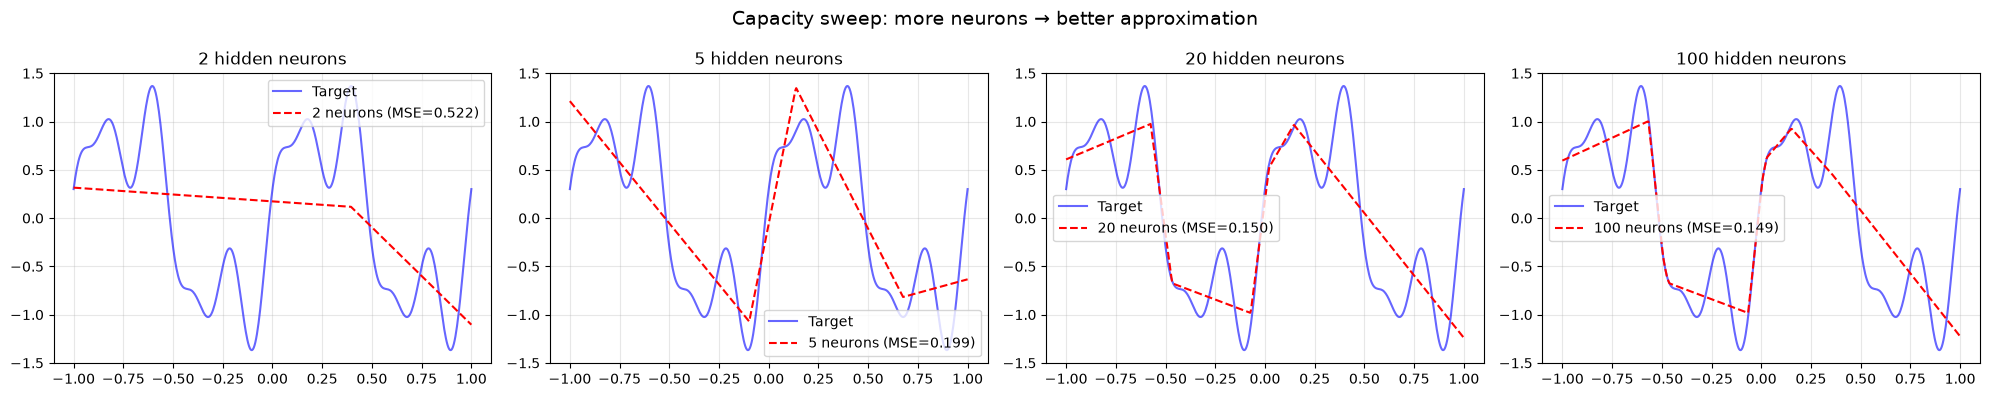


=== 2. Activation alternatives ===


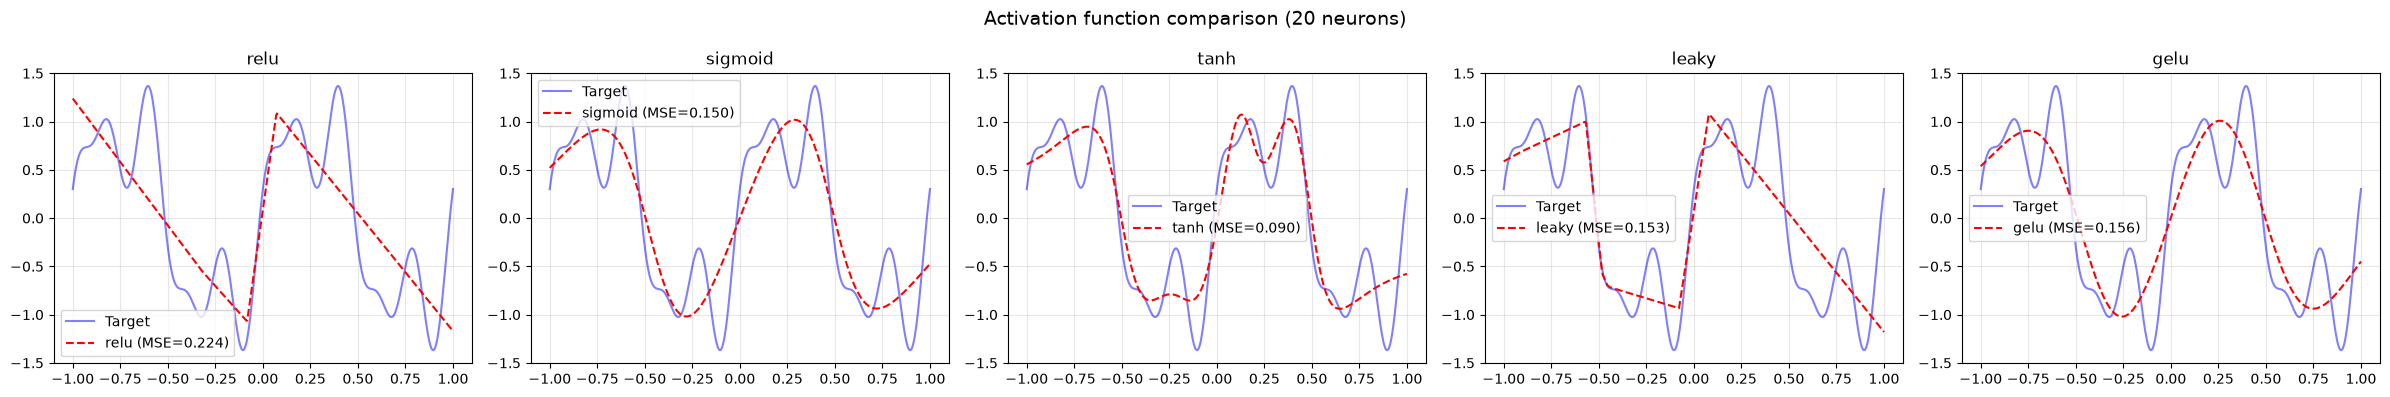

Activation MSEs: {'relu': 0.2240760326385498, 'sigmoid': 0.15014678239822388, 'tanh': 0.09025417268276215, 'leaky': 0.15346597135066986, 'gelu': 0.15625181794166565}

=== 3. Deeper + thinner ===


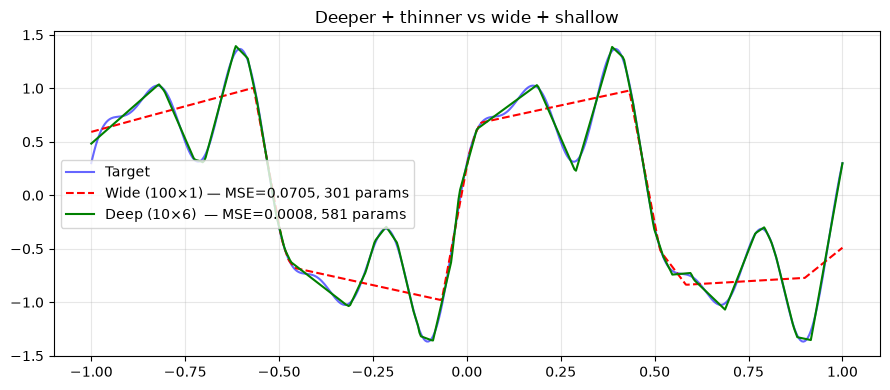


=== 4. Four failure modes ===


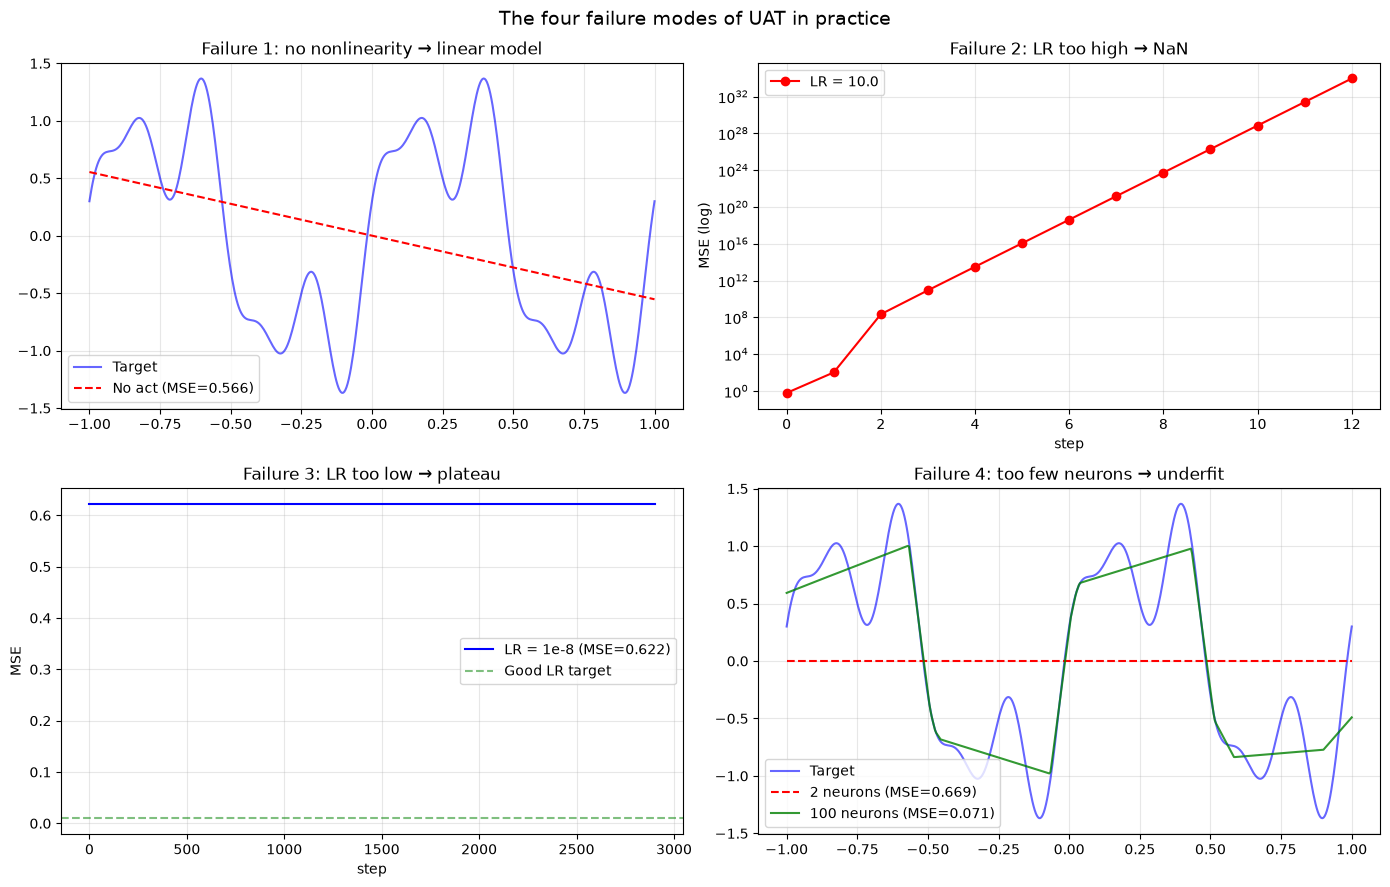


=== 5. Summary dashboard ===


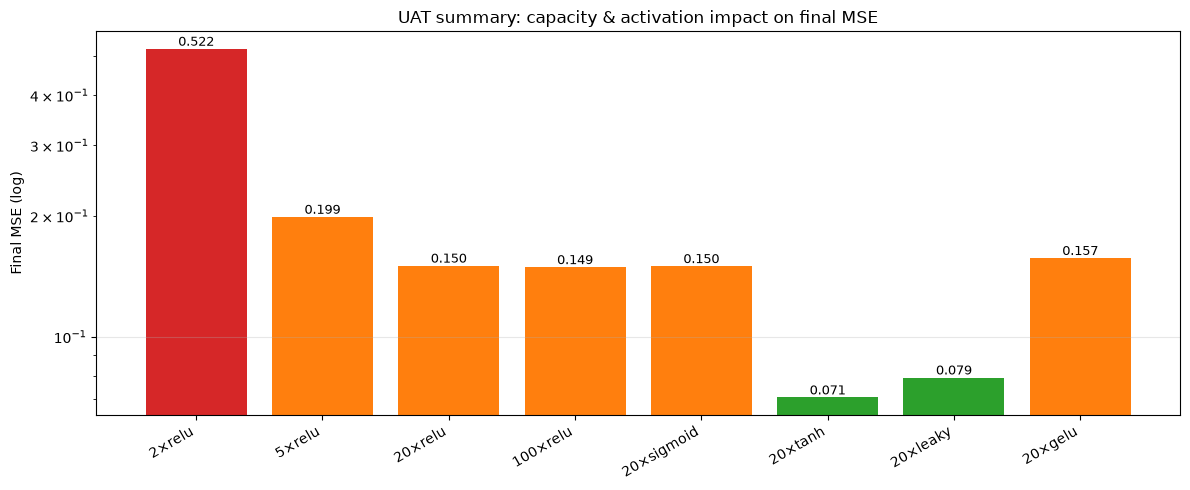

In [14]:
"""
Universal Approximation Theorem — complete demo
Covers: capacity sweep, activation alternatives, deeper+thin,
        4 failure modes, diagnostic dashboard.
Run: python uat_demo.py
"""
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ─────────────────────────────────────────────────────────────
# 0. Setup
# ─────────────────────────────────────────────────────────────
torch.manual_seed(42)
np.random.seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def target_function(x):
    """Sum of three sinusoids — the function we want to approximate."""
    return (np.sin(2 * np.pi * x)
            + 0.5 * np.sin(6 * np.pi * x)
            + 0.3 * np.cos(10 * np.pi * x))


x_data = np.linspace(-1, 1, 500).reshape(-1, 1).astype(np.float32)
y_data = target_function(x_data).astype(np.float32)
X = torch.tensor(x_data, device=DEVICE)
y = torch.tensor(y_data, device=DEVICE)


# ─────────────────────────────────────────────────────────────
# 1. Model zoo — one hidden layer, pluggable activation
# ─────────────────────────────────────────────────────────────
class UATNet(nn.Module):
    def __init__(self, n_hidden, activation="relu"):
        super().__init__()
        self.hidden = nn.Linear(1, n_hidden)
        self.output = nn.Linear(n_hidden, 1)
        self.act_name = activation

    def forward(self, x):
        h = self.hidden(x)
        a = self.act_name
        if   a == "relu":    h = torch.relu(h)
        elif a == "sigmoid": h = torch.sigmoid(h)
        elif a == "tanh":    h = torch.tanh(h)
        elif a == "leaky":   h = nn.functional.leaky_relu(h, 0.01)
        elif a == "gelu":    h = nn.functional.gelu(h)
        elif a == "none":    pass                    # deliberately broken
        else: raise ValueError(a)
        return self.output(h)


class UATDeep(nn.Module):
    """Deeper + thinner: same capacity, fewer parameters."""
    def __init__(self, width=10, depth=3):
        super().__init__()
        layers = [nn.Linear(1, width), nn.ReLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.ReLU()]
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# ─────────────────────────────────────────────────────────────
# 2. Training helper
# ─────────────────────────────────────────────────────────────
def train(model, lr=0.01, steps=3000, opt_name="adam",
          clip=None, record_every=None, verbose=False):
    """Train and return (prediction, loss_history, final_loss)."""
    if opt_name == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr)

    crit = nn.MSELoss()
    history = []
    model.train()
    for step in range(steps):
        opt.zero_grad()
        loss = crit(model(X), y)
        loss.backward()
        if clip is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        opt.step()

        if record_every and step % record_every == 0:
            history.append(loss.item())

        if torch.isnan(loss):
            if verbose:
                print(f"  NaN at step {step}")
            return None, history, float("nan")

    model.eval()
    with torch.no_grad():
        pred = model(X).cpu().numpy()
    final = loss.item()
    if verbose:
        print(f"  final MSE: {final:.5f}")
    return pred, history, final


# ─────────────────────────────────────────────────────────────
# 3. Capacity sweep — more neurons, better fit
# ─────────────────────────────────────────────────────────────
def experiment_capacity():
    widths = [2, 5, 20, 100]
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for ax, n in zip(axes, widths):
        torch.manual_seed(42)
        model = UATNet(n, "relu")
        pred, _, mse = train(model, lr=0.01, steps=3000)
        ax.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
        ax.plot(x_data, pred, 'r--', label=f'{n} neurons (MSE={mse:.3f})')
        ax.set_title(f'{n} hidden neurons')
        ax.legend(); ax.grid(alpha=0.3)
    plt.suptitle('Capacity sweep: more neurons → better approximation', fontsize=14)
    plt.tight_layout(); plt.show()


# ─────────────────────────────────────────────────────────────
# 4. Activation alternatives
# ─────────────────────────────────────────────────────────────
def experiment_activations():
    acts = ["relu", "sigmoid", "tanh", "leaky", "gelu"]
    results = {}
    fig, axes = plt.subplots(1, 5, figsize=(24, 4))
    for ax, a in zip(axes, acts):
        torch.manual_seed(1234)
        model = UATNet(20, a)
        pred, _, mse = train(model, lr=0.01, steps=1500)
        results[a] = mse
        ax.plot(x_data, y_data, 'b-', alpha=0.5, label='Target')
        ax.plot(x_data, pred, 'r--', label=f'{a} (MSE={mse:.3f})')
        ax.set_title(a); ax.legend(); ax.grid(alpha=0.3)
    plt.suptitle('Activation function comparison (20 neurons)', fontsize=14)
    plt.tight_layout(); plt.show()
    print("Activation MSEs:", results)


# ─────────────────────────────────────────────────────────────
# 5. Deeper + thinner
# ─────────────────────────────────────────────────────────────
def experiment_deep_thin():
    torch.manual_seed(0)
    wide  = UATNet(100, "relu")
    deep  = UATDeep(width=10, depth=6)
    n_wide = sum(p.numel() for p in wide.parameters())
    n_deep = sum(p.numel() for p in deep.parameters())

    pred_w, _, mse_w = train(wide, lr=0.01, steps=3000)
    pred_d, _, mse_d = train(deep, lr=0.01, steps=3000)

    plt.figure(figsize=(9, 4))
    plt.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
    plt.plot(x_data, pred_w, 'r--', label=f'Wide (100×1) — MSE={mse_w:.4f}, {n_wide} params')
    plt.plot(x_data, pred_d, 'g-',  label=f'Deep (10×6)  — MSE={mse_d:.4f}, {n_deep} params')
    plt.title('Deeper + thinner vs wide + shallow')
    plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


# ─────────────────────────────────────────────────────────────
# 6. The four failure modes
# ─────────────────────────────────────────────────────────────
def failure_1_no_nonlinearity(ax):
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(1, 64),
                        nn.Linear(64, 64),          # no ReLU!
                        nn.Linear(64, 1)).to(DEVICE)
    pred, _, mse = train(net, lr=0.01, steps=3000)
    ax.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
    ax.plot(x_data, pred, 'r--', label=f'No act (MSE={mse:.3f})')
    ax.set_title('Failure 1: no nonlinearity → linear model')
    ax.legend(); ax.grid(alpha=0.3)


def failure_2_lr_high(ax):
    torch.manual_seed(0)
    m = nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Linear(32, 1)).to(DEVICE)
    opt = torch.optim.SGD(m.parameters(), lr=10.0)
    losses = []
    m.train()
    for step in range(30):
        opt.zero_grad()
        loss = nn.MSELoss()(m(X), y)
        loss.backward(); opt.step()
        losses.append(loss.item())
        if torch.isnan(loss): break
    ax.plot(losses, 'r-o', label='LR = 10.0')
    ax.set_yscale('log')
    ax.set_title('Failure 2: LR too high → NaN')
    ax.set_xlabel('step'); ax.set_ylabel('MSE (log)')
    ax.legend(); ax.grid(alpha=0.3)


def failure_3_lr_low(ax):
    torch.manual_seed(0)
    m = nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Linear(32, 1)).to(DEVICE)
    _, hist, final = train(m, lr=1e-8, steps=3000,
                           opt_name="sgd", record_every=100)
    ax.plot(np.arange(len(hist)) * 100, hist, 'b-', label=f'LR = 1e-8 (MSE={final:.3f})')
    ax.axhline(0.01, color='g', ls='--', alpha=0.5, label='Good LR target')
    ax.set_title('Failure 3: LR too low → plateau')
    ax.set_xlabel('step'); ax.set_ylabel('MSE')
    ax.legend(); ax.grid(alpha=0.3)


def failure_4_too_few(ax):
    torch.manual_seed(0)
    small = nn.Sequential(nn.Linear(1, 2), nn.ReLU(), nn.Linear(2, 1)).to(DEVICE)
    torch.manual_seed(0)
    big   = nn.Sequential(nn.Linear(1, 100), nn.ReLU(), nn.Linear(100, 1)).to(DEVICE)
    pred_s, _, mse_s = train(small, lr=0.01, steps=3000)
    pred_b, _, mse_b = train(big,   lr=0.01, steps=3000)
    ax.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
    ax.plot(x_data, pred_s, 'r--', label=f'2 neurons (MSE={mse_s:.3f})')
    ax.plot(x_data, pred_b, 'g-',  alpha=0.8, label=f'100 neurons (MSE={mse_b:.3f})')
    ax.set_title('Failure 4: too few neurons → underfit')
    ax.legend(); ax.grid(alpha=0.3)


def experiment_failures():
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    failure_1_no_nonlinearity(axes[0, 0])
    failure_2_lr_high(axes[0, 1])
    failure_3_lr_low(axes[1, 0])
    failure_4_too_few(axes[1, 1])
    plt.suptitle('The four failure modes of UAT in practice', fontsize=14)
    plt.tight_layout(); plt.show()


# ─────────────────────────────────────────────────────────────
# 7. Summary dashboard
# ─────────────────────────────────────────────────────────────
def summary_dashboard():
    torch.manual_seed(0)

    # collect MSE values
    runs = []
    for n, a in [(2, "relu"), (5, "relu"), (20, "relu"), (100, "relu")]:
        torch.manual_seed(42)
        _, _, mse = train(UATNet(n, a), lr=0.01, steps=3000)
        runs.append((f"{n}×relu", mse))

    for a in ["sigmoid", "tanh", "leaky", "gelu"]:
        torch.manual_seed(42)
        _, _, mse = train(UATNet(20, a), lr=0.01, steps=1500)
        runs.append((f"20×{a}", mse))

    labels = [r[0] for r in runs]
    mses   = [r[1] for r in runs]

    plt.figure(figsize=(12, 5))
    colors = ['#d62728' if m > 0.3 else '#ff7f0e' if m > 0.1 else '#2ca02c'
              for m in mses]
    bars = plt.bar(labels, mses, color=colors)
    plt.yscale('log')
    plt.ylabel('Final MSE (log)')
    plt.title('UAT summary: capacity & activation impact on final MSE')
    plt.xticks(rotation=30, ha='right')
    for bar, m in zip(bars, mses):
        plt.text(bar.get_x() + bar.get_width()/2, m,
                 f'{m:.3f}', ha='center', va='bottom', fontsize=9)
    plt.grid(alpha=0.3, axis='y')
    plt.tight_layout(); plt.show()


# ─────────────────────────────────────────────────────────────
# 8. Run everything
# ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    print("=== 1. Capacity sweep ===")
    experiment_capacity()

    print("\n=== 2. Activation alternatives ===")
    experiment_activations()

    print("\n=== 3. Deeper + thinner ===")
    experiment_deep_thin()

    print("\n=== 4. Four failure modes ===")
    experiment_failures()

    print("\n=== 5. Summary dashboard ===")
    summary_dashboard()

### Exploration

In [31]:
import torch, torch.nn as nn, numpy as np, matplotlib.pyplot as plt

torch.manual_seed(42); np.random.seed(42)

# ---- targets as a dict comprehension -----------------------------
TARGET_DEFS = {
    "three_sine": "np.sin(2*np.pi*x) + 0.5*np.sin(6*np.pi*x) + 0.3*np.cos(10*np.pi*x)",
    "high_freq":  "np.sin(20*np.pi*x)",
    "abs":        "np.abs(x)",
    "tanh5":      "np.tanh(5*x)",
    "linear":     "3*x + 2",
    "piecewise":  "np.where(x < 0, x, x**2)",
}
TARGETS = {name: eval(f"lambda x: {expr}") for name, expr in TARGET_DEFS.items()}

target = TARGETS["three_sine"]      # EXPLORE: change the key

# ---- data --------------------------------------------------------
DOMAIN, N = (-1, 1), 500
x_data = np.linspace(*DOMAIN, N).reshape(-1, 1).astype(np.float32)
y_data = np.array([target(xi) for xi in x_data], dtype=np.float32).reshape(-1, 1)
X = torch.tensor(x_data)
y = torch.tensor(y_data)

# ---- activations as a dict comprehension -------------------------
ACT_DEFS = {
    "relu":    "torch.relu(h)",
    "sigmoid": "torch.sigmoid(h)",
    "tanh":    "torch.tanh(h)",
    "leaky":   "nn.functional.leaky_relu(h, 0.01)",
    "gelu":    "nn.functional.gelu(h)",
    "none":    "h",
}
ACT_FNS = {name: eval(f"lambda h: {expr}") for name, expr in ACT_DEFS.items()}

# ---- models ------------------------------------------------------
class Net(nn.Module):
    def __init__(self, n_hidden=20, act="relu"):
        super().__init__()
        self.h = nn.Linear(1, n_hidden)
        self.o = nn.Linear(n_hidden, 1)
        self.act = act
    def forward(self, x):
        return self.o(ACT_FNS[self.act](self.h(x)))

class DeepNet(nn.Module):
    def __init__(self, width=10, depth=6, act="relu"):
        super().__init__()
        layers = [nn.Linear(1, width)]
        for _ in range(depth):
            layers += [nn.Linear(width, width)]
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)
        self.act = act
    def forward(self, x):
        h = x
        for i, layer in enumerate(self.net):
            h = layer(h)
            if i < len(self.net) - 1:
                h = ACT_FNS[self.act](h)
        return h

# ---- trainers ----------------------------------------------------
def train(model, lr=0.01, steps=3000, opt="adam"):
    """Returns (pred, mse). pred is None if NaN occurred."""
    O = torch.optim.Adam if opt == "adam" else torch.optim.SGD
    optimizer = O(model.parameters(), lr=lr)
    model.train()
    for _ in range(steps):
        optimizer.zero_grad()
        loss = ((model(X) - y) ** 2).mean()
        loss.backward()
        optimizer.step()
        if torch.isnan(loss):
            return None, float("nan")
    model.eval()
    with torch.no_grad():
        pred = model(X).numpy()
    return pred, loss.item()

def train_hist(model, lr=0.01, steps=3000, opt="adam"):
    """Returns (pred, losses, mse). pred is None if NaN occurred."""
    O = torch.optim.Adam if opt == "adam" else torch.optim.SGD
    optimizer = O(model.parameters(), lr=lr)
    model.train()
    losses = []
    for _ in range(steps):
        optimizer.zero_grad()
        loss = ((model(X) - y) ** 2).mean()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if torch.isnan(loss):
            return None, losses, float("nan")
    model.eval()
    with torch.no_grad():
        pred = model(X).numpy()
    return pred, losses, losses[-1]

# ---- plotting helper --------------------------------------------
def plot_fit(ax, pred, title, label=None, mse=None):
    ax.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
    if pred is not None:
        lbl = label or 'Model'
        if mse is not None:
            lbl += f'  MSE={mse:.3f}'
        ax.plot(x_data, pred, 'r--', label=lbl)
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)

# ---- sanity check (list comp) ------------------------------------
checks = [(a, train(Net(20, a))[1]) for a in ACT_FNS]              # list comp
print({a: f"{m:.4f}" for a, m in checks})                          # dict comp

{'relu': '0.1503', 'sigmoid': '0.1181', 'tanh': '0.0387', 'leaky': '0.0739', 'gelu': '0.1502', 'none': '0.5663'}


One ReLU neuron

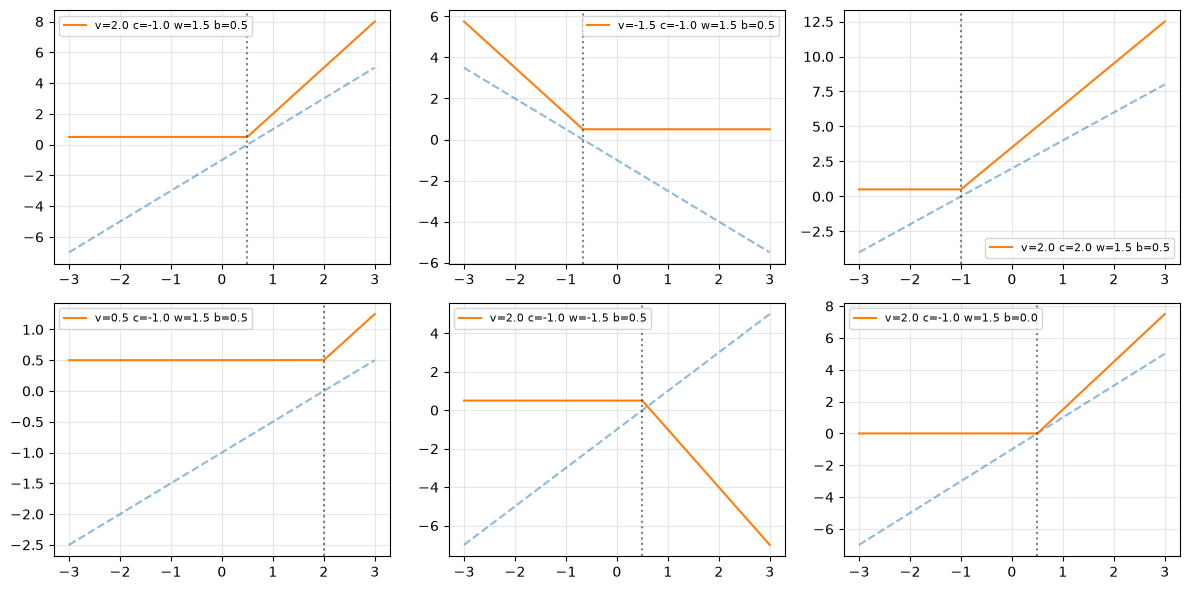

In [30]:
xs = np.linspace(-3, 3, 500)

configs = [(v, c, w, b) for v, c, w, b in
           [( 2.0, -1.0,  1.5, 0.5),
            (-1.5, -1.0,  1.5, 0.5),
            ( 2.0,  2.0,  1.5, 0.5),
            ( 0.5, -1.0,  1.5, 0.5),
            ( 2.0, -1.0, -1.5, 0.5),
            ( 2.0, -1.0,  1.5, 0.0)]]                              # list comp

curves = [(v, c, w, b, v*xs + c, np.maximum(0, v*xs + c),
           w * np.maximum(0, v*xs + c) + b) for v, c, w, b in configs]  # list comp

fig, axes = plt.subplots(2, 3, figsize=(12, 6)); axes = axes.flatten()
[ (ax.plot(xs, pre, '--', alpha=0.5),
   ax.plot(xs, out, label=f'v={v} c={c} w={w} b={b}'),
   ax.axvline(-c/v, color='k', ls=':', alpha=0.5),
   ax.legend(fontsize=8), ax.grid(alpha=0.3))
  for ax, (v, c, w, b, pre, post, out) in zip(axes, curves) ]      # list comp
plt.tight_layout(); plt.show()

width sweep

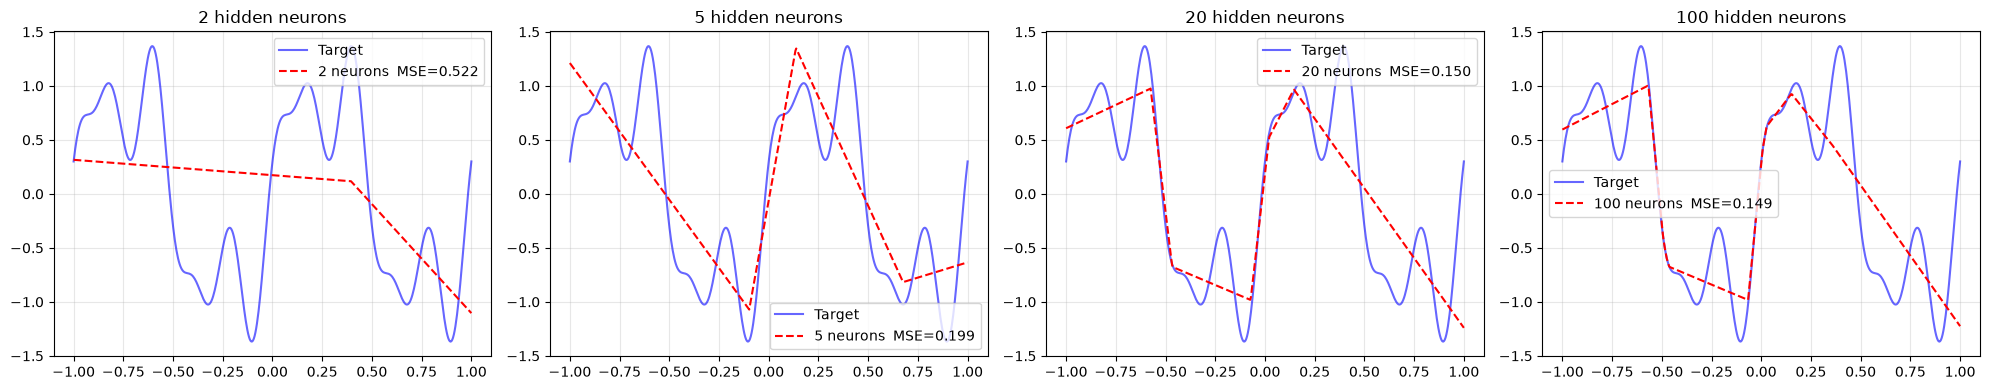

MSEs: {2: '0.5220', 5: '0.1989', 20: '0.1503', 100: '0.1490'}


In [32]:
widths = [2, 5, 20, 100]

fig, axes = plt.subplots(1, len(widths), figsize=(20, 4))
mses = []
for ax, n in zip(axes, widths):
    torch.manual_seed(42)
    pred, mse = train(Net(n, "relu"))
    mses.append(mse)
    ax.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
    ax.plot(x_data, pred,   'r--', label=f'{n} neurons  MSE={mse:.3f}')
    ax.set_title(f'{n} hidden neurons'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("MSEs:", dict(zip(widths, [f"{m:.4f}" for m in mses])))

Activation sweep

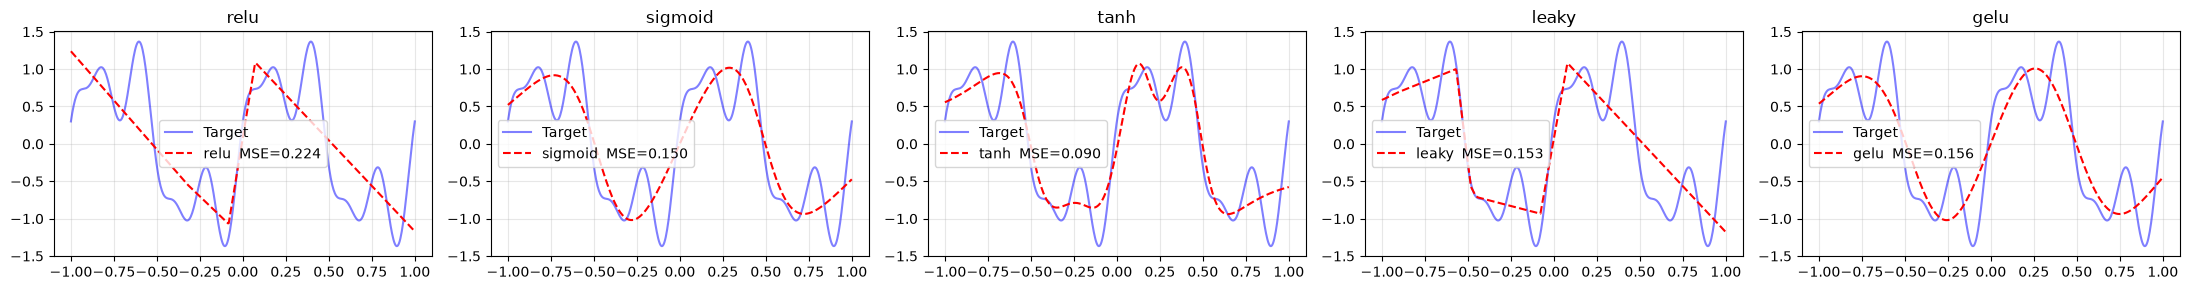

MSEs: {'relu': '0.2241', 'sigmoid': '0.1501', 'tanh': '0.0903', 'leaky': '0.1535', 'gelu': '0.1563'}


In [33]:
acts = ["relu", "sigmoid", "tanh", "leaky", "gelu"]

fig, axes = plt.subplots(1, len(acts), figsize=(22, 3))
mses = {}
for ax, a in zip(axes, acts):
    torch.manual_seed(1234)
    pred, mse = train(Net(20, a), steps=1500)
    mses[a] = mse
    ax.plot(x_data, y_data, 'b-', alpha=0.5, label='Target')
    ax.plot(x_data, pred,   'r--', label=f'{a}  MSE={mse:.3f}')
    ax.set_title(a); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("MSEs:", {k: f"{v:.4f}" for k, v in mses.items()})

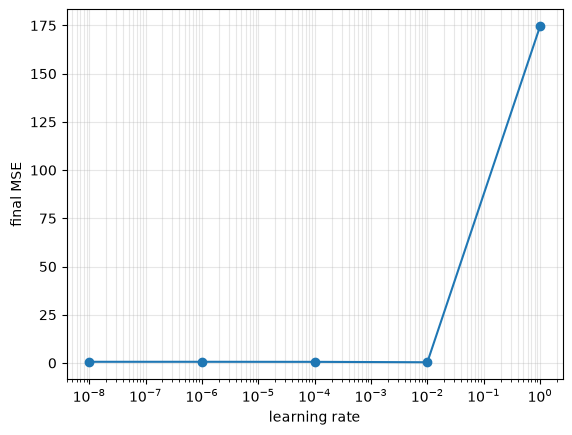

{1e-08: '0.6224', 1e-06: '0.6216', 0.0001: '0.5904', 0.01: '0.3816', 1.0: '174.5950', 10.0: 'nan'}


In [ ]:
lrs = [1e-8, 1e-6, 1e-4, 1e-2, 1.0, 10.0]
results = {}
for lr in lrs:
    torch.manual_seed(0)
    m = nn.Sequential(nn.Linear(1,32), nn.ReLU(), nn.Linear(32,1))
    _, mse = train(m, lr=lr, steps=3000, opt="sgd")
    results[lr] = mse

plt.semilogx(lrs, [results[l] for l in lrs], 'o-')                  
plt.xlabel('learning rate'); plt.ylabel('final MSE')
plt.grid(alpha=0.3, which='both'); plt.show()
print({l: f"{m:.4f}" for l, m in results.items()})

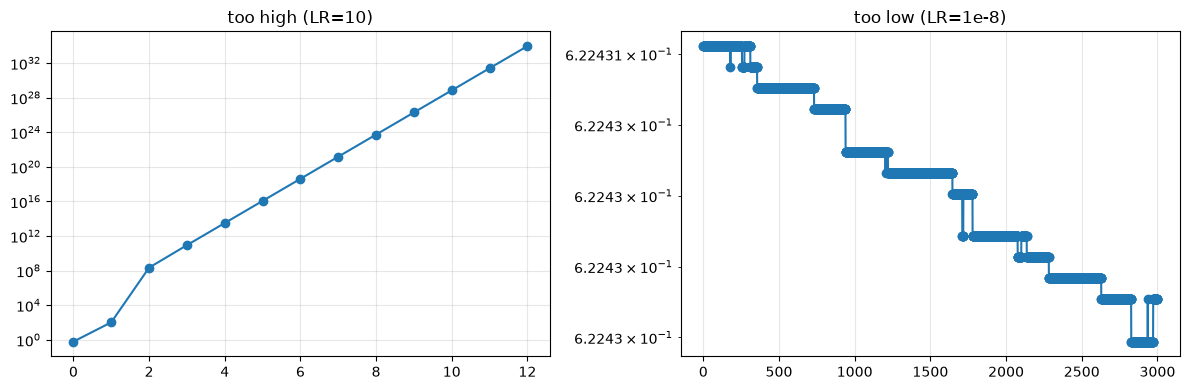

In [35]:
def run_lr_history(lr, steps):
    torch.manual_seed(0)
    m = nn.Sequential(nn.Linear(1,32), nn.ReLU(), nn.Linear(32,1))
    _, losses, _ = train_hist(m, lr=lr, steps=steps, opt="sgd")
    return losses

configs = [("too high (LR=10)",   10.0,   20),
           ("too low (LR=1e-8)",  1e-8, 3000)]

runs = [(name, run_lr_history(lr, steps)) for name, lr, steps in configs]  # list comp

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
[ (ax.plot(hist, '-o'), ax.set_yscale('log'),
   ax.set_title(name), ax.grid(alpha=0.3))
  for ax, (name, hist) in zip(axes, runs) ]                          # list comp
plt.tight_layout(); plt.show()

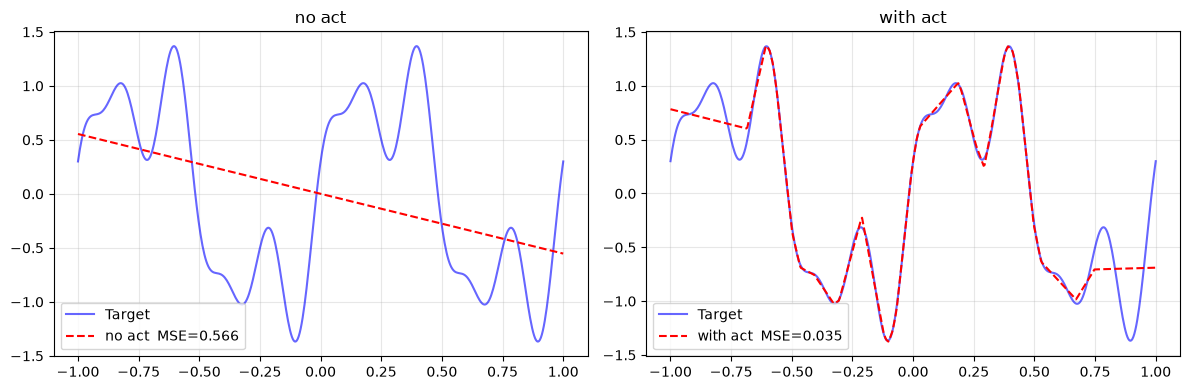

In [36]:
def build_no_act():
    return nn.Sequential(nn.Linear(1,64), nn.Linear(64,64), nn.Linear(64,1))

def build_with_act():
    return nn.Sequential(nn.Linear(1,64), nn.ReLU(),
                         nn.Linear(64,64), nn.ReLU(),
                         nn.Linear(64,1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, build) in zip(axes, [("no act", build_no_act),
                                    ("with act", build_with_act)]):
    torch.manual_seed(0)
    pred, mse = train(build(), lr=0.01, steps=3000)
    ax.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
    ax.plot(x_data, pred, 'r--', label=f'{name}  MSE={mse:.3f}')
    ax.set_title(name); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

too few vs enough

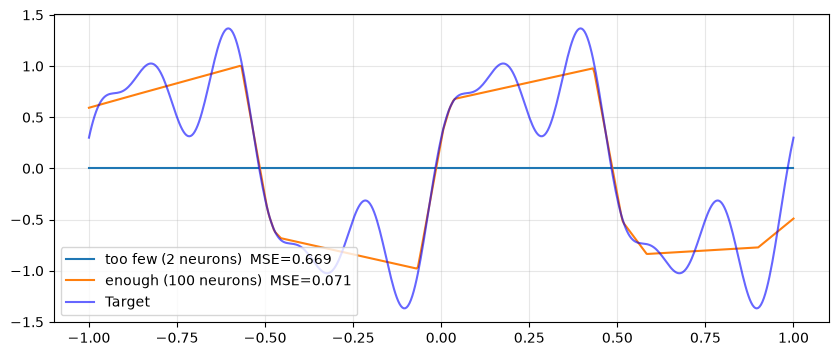

In [37]:
configs = [(2, "too few"), (100, "enough")]

plt.figure(figsize=(10, 4))
for n, name in configs:
    torch.manual_seed(0)
    pred, mse = train(Net(n, "relu"), lr=0.01, steps=3000)
    plt.plot(x_data, pred, label=f'{name} ({n} neurons)  MSE={mse:.3f}')
plt.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
plt.legend(); plt.grid(alpha=0.3); plt.show()

Deep vs wide

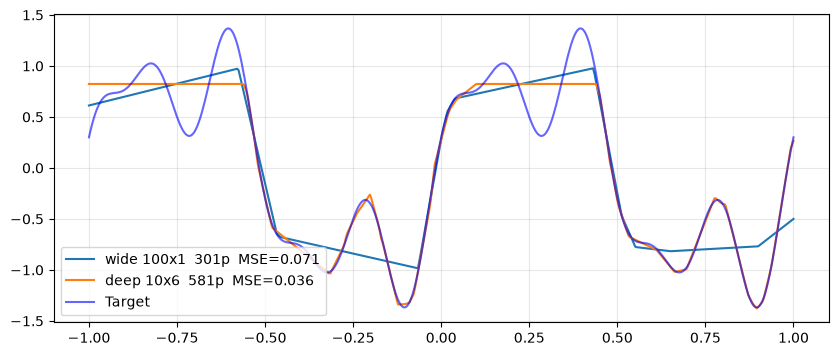

In [38]:
class DeepNet(nn.Module):
    def __init__(self, width=10, depth=6):
        super().__init__()
        layers = [nn.Linear(1, width), nn.ReLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.ReLU()]
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

plt.figure(figsize=(10, 4))
for name, m in [("wide 100x1", Net(100, "relu")),
                ("deep 10x6",  DeepNet(width=10, depth=6))]:
    torch.manual_seed(0)
    pred, mse = train(m)
    plt.plot(x_data, pred,
             label=f'{name}  {sum(p.numel() for p in m.parameters())}p  MSE={mse:.3f}')
plt.plot(x_data, y_data, 'b-', alpha=0.6, label='Target')
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [39]:
def summarize():
    w = {n: (torch.manual_seed(42), train(Net(n, "relu")))[1][1] for n in [2, 5, 20, 100]}
    a = {name: (torch.manual_seed(1234), train(Net(20, name), steps=1500))[1][1]
         for name in ACT_FNS}                                       # dict comp
    l = {lr: (torch.manual_seed(0),
              train(nn.Sequential(nn.Linear(1,32), nn.ReLU(), nn.Linear(32,1)),
                    lr=lr, steps=3000, opt="sgd"))[1][1]
         for lr in [1e-8, 1e-4, 1e-2, 1.0, 10.0]}                   # dict comp
    return w, a, l

w, a, l = summarize()
print("width  :", {k: f"{v:.4f}" for k, v in w.items()})
print("act    :", {k: f"{v:.4f}" for k, v in a.items()})
print("lr     :", {k: f"{v:.4f}" for k, v in l.items()})
print("best w :", min(w, key=w.get))
print("best a :", min(a, key=a.get))
print("best lr:", min(l, key=l.get))

width  : {2: '0.5220', 5: '0.1989', 20: '0.1503', 100: '0.1490'}
act    : {'relu': '0.2241', 'sigmoid': '0.1501', 'tanh': '0.0903', 'leaky': '0.1535', 'gelu': '0.1563', 'none': '0.5663'}
lr     : {1e-08: '0.6224', 0.0001: '0.5904', 0.01: '0.3816', 1.0: '174.5950', 10.0: 'nan'}
best w : 100
best a : tanh
best lr: 0.01
